# Electrophysiological profiling for PV140

Publication-ready version of the `estimate_depth.ipynb` workflow. The notebook loads the PV140 Neuropixels recording, extracts one probe column, applies LFP preprocessing with the C-factor correction used in the draft, estimates the brain boundary from frequency-band power profiles, and exports each final figure as one page in a single PDF.

Run the notebook top-to-bottom on the server. The local validation here checks code structure only and does not load or process the recording.

## Configuration

In [58]:
from pathlib import Path

# Recording identity
RECORDING_ID = "PV140"
META_PATH = Path(
    "/media/sil3/Data/Large_scale_mapping_NP/lizards/PV140/"
    "PV140_Experiment_4_6_25/"
    "PV140_Experiment_4_6_25_testWholeShank_g0/"
    "PV140_Experiment_4_6_25_testWholeShank_g0_imec0/"
    "PV140_Experiment_4_6_25_testWholeShank_g0_t0.imec0.ap.meta"
)

# Probe column used for the depth profile. These are the values used in the draft.
SHANK = 0
X_COORD = 27

# Data window. Use None for the whole recording.
LOAD_START_S = 0.0
LOAD_DURATION_S = None

# LFP preprocessing
LINE_NOISE_HZ = 50.0
LOWPASS_HZ = 300.0
DOWNSAMPLED_RATE_HZ = 1000.0
PREPROCESS_BATCH_S = 60.0
FILTER_OVERLAP_S = 2.0
APPLY_POST_RESAMPLE_NOTCH = False

# C-factor correction: expected signal is estimated by smoothing across depth.
# Draft setting for these PV140 figures: subtract median(signal) per channel, then
# estimate/apply the C-factor on the same 2 s window.
MATCH_DRAFT_FINAL_STATE = False
C_FACTOR_SIGMA_CHANNELS = 3
C_FACTOR_CLIP = None
APPLY_COMMON_MEDIAN_REFERENCE = False

# Spectral/depth profiling. Match estimate_depth.ipynb ordering:
# 1) preprocess the full selected shank/column;
# 2) take the middle 2 * DUR_PREP_S window;
# 3) inside that middle window, take a 2 s analysis excerpt starting at 100 s;
# 4) subtract median(signal) per channel and apply the C-factor to that 2 s excerpt.
NFFT = 4096
FREQUENCY_BANDS = [(1.5, 4.0), (4.0, 10.0), (10.0, 30.0), (30.0, 80.0), (80.0, 200.0)]
BOUNDARY_N_SEGMENTS = 6
MIN_POINTS_PER_SEGMENT = 8
DUR_PREP_S = 1.5 * 60
PROFILE_START_S = 100.0
PROFILE_DURATION_S = 2.0
USE_DRAFT_PV140_BREAKPOINTS = False
DRAFT_PV140_BREAKPOINTS_UM = [2535.0, 2460.0, 2460.0, 2550.9, 2550.2]

# Trace panel (figure E), relative to the final 2 s corrected excerpt.
TRACE_START_S = 0.0
TRACE_DURATION_S = 2.0
TRACE_CHANNEL_STEP = 1
N_LFP_TRACE_CLUSTERS = 10

# Optional second trace PDF using the alternative low40 LFP preprocessing:
# take the same analysis window from full-rate selected data, low-pass at 40 Hz,
# subtract median(signal), then apply the C-factor. No peak/event alignment is used.
MAKE_LOW40_PREPROCESSED_TRACE_PDF = True
LOW40_LOWPASS_HZ = 40.0
LOW40_DOWNSAMPLED_RATE_HZ = 1000.0
LOW40_TRACE_SCALE = 0.25
LOW40_CSD_SIGMA = [5, 5]
LOW40_CSD_PERCENTILE = 95

# Output
OUTPUT_DIR = Path("../results")
PDF_PATH = OUTPUT_DIR / f"{RECORDING_ID}_electrophysiological_profiling.pdf"
FIG_DPI = 300


## Imports

In [72]:
import os
import sys
from pathlib import Path
import json

current_dir = os.getcwd()
parent_dir = os.path.dirname(current_dir)
sys.path.append(parent_dir)


import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.backends.backend_pdf import PdfPages
from scipy import signal
from scipy.ndimage import gaussian_filter, gaussian_filter1d
from scipy.cluster.hierarchy import linkage, fcluster
from sklearn.neighbors import kneighbors_graph
from sklearn.cluster import AgglomerativeClustering

PROJECT_ROOT = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
# Keep the repository root first so `neuropix.neuropix` resolves like in the original project notebooks.
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from neuropix.neuropix import analyze, io, pipeline
from neuropix.neuropix.pipeline import PipelineWrap
from neuropix.neuropix.signal import processing, FuncWrap

OUTPUT_DIR = PROJECT_ROOT / "results" / "electrophysiological_profiling" / RECORDING_ID
PDF_PATH = OUTPUT_DIR / f"{RECORDING_ID}_electrophysiological_profiling.pdf"

plt.rcParams.update({
    "figure.dpi": 120,
    "savefig.dpi": FIG_DPI,
    "font.family": "DejaVu Sans",
    "font.size": 9,
    "axes.titlesize": 10,
    "axes.labelsize": 9,
    "legend.fontsize": 7,
    "xtick.labelsize": 8,
    "ytick.labelsize": 8,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.unicode_minus": False,
    "pdf.fonttype": 42,
    "ps.fonttype": 42,
    "svg.fonttype": "none",
})



## Data loading and preprocessing helpers

In [60]:
def build_electrode_info(metadata):
    n_ap = int(metadata["n_ap_channels"])
    return pd.DataFrame({
        "electrode_id": np.arange(n_ap),
        "x": np.asarray(metadata["x_coords"][:n_ap]),
        "y": np.asarray(metadata["y_coords"][:n_ap]),
        "shank": np.asarray(metadata["shank_number"][:n_ap]),
    })


def select_probe_column(electrode_info, shank, x_coord):
    column = electrode_info[(electrode_info["shank"] == shank) & (electrode_info["x"] == x_coord)].copy()
    if column.empty:
        available = electrode_info.groupby(["shank", "x"]).size().reset_index(name="n")
        raise ValueError(f"No electrodes found for shank={shank}, x={x_coord}. Available combinations:\n{available}")
    column = column.sort_values("y")
    return column["electrode_id"].to_numpy(dtype=int), column["y"].to_numpy(dtype=float)


def load_recording_column(meta_path, shank, x_coord, start_s=0.0, duration_s=None):
    metadata, metadata_raw = io.parse_metadata(meta_path)
    electrode_info = build_electrode_info(metadata)
    channel_idx, depth_um = select_probe_column(electrode_info, shank=shank, x_coord=x_coord)

    if duration_s is None:
        duration_s = metadata["duration"] - start_s
    bin_path = Path(str(meta_path).replace(".imec0.ap.meta", ".imec0.ap.bin"))
    if not bin_path.exists():
        raise FileNotFoundError(f"Binary file was not found next to metadata: {bin_path}")

    data, time, _ = io.get_data(
        file_path=bin_path,
        metadata=metadata,
        start_times=[start_s],
        window=duration_s,
        channels=[0],
        convert_to_uv=True,
        get_all_channels=True,
    )
    ap_data = data[0, : int(metadata["n_ap_channels"]), :]
    return ap_data[channel_idx].astype(np.float32), time[0], metadata, metadata_raw, electrode_info, channel_idx, depth_um


def preprocess_lfp(data, time, fs):
    functions = [
        FuncWrap(processing, "notch_filter", freq=LINE_NOISE_HZ, fs=fs, q=30.0, axis=1),
        FuncWrap(processing, "lowpass_filter", lowcut=LOWPASS_HZ, fs=fs, axis=1),
        FuncWrap(processing, "resample_torch", fs=fs, new_fs=DOWNSAMPLED_RATE_HZ, axis=1),
    ]
    pipeline_1 = PipelineWrap(
        pipeline,
        "apply_preprocess",
        functions=functions,
        batch_mode=True,
        batch_size=1024 * 1024,
        overlap=1024,
    )
    preprocessed, new_time, new_fs = pipeline_1(data, time, fs)
    preprocessed = preprocessed.astype(np.float32, copy=False)
    if APPLY_POST_RESAMPLE_NOTCH:
        post_notch = processing.notch_filter(freq=LINE_NOISE_HZ, fs=float(new_fs), q=30.0, axis=1)
        preprocessed = post_notch(preprocessed).astype(np.float32, copy=False)
    return preprocessed, new_time, float(new_fs)


def apply_c_factor(data):
    centered = data - np.median(data, axis=1, keepdims=True)
    if APPLY_COMMON_MEDIAN_REFERENCE:
        centered = centered - np.median(centered, axis=0, keepdims=True)

    expected = gaussian_filter1d(centered, sigma=C_FACTOR_SIGMA_CHANNELS, axis=0, mode="nearest")
    c_samples = np.divide(expected, centered, out=np.ones_like(centered), where=centered != 0)
    c_factor = np.median(c_samples, axis=1)
    c_factor = np.where(np.isfinite(c_factor), c_factor, 1.0)
    if C_FACTOR_CLIP is not None:
        c_factor = np.clip(c_factor, C_FACTOR_CLIP[0], C_FACTOR_CLIP[1])
    corrected = centered * c_factor[:, None]
    return corrected.astype(np.float32, copy=False), c_factor


def cluster_lfp_by_correlation(corr_matrix, n_clusters=N_LFP_TRACE_CLUSTERS, max_gap=3):
    indices = np.arange(corr_matrix.shape[0]).reshape(-1, 1)
    connectivity = kneighbors_graph(indices, n_neighbors=2 * max_gap, mode="connectivity")
    clustering = AgglomerativeClustering(
        n_clusters=n_clusters,
        connectivity=connectivity,
        linkage="ward",
    )
    return clustering.fit_predict(corr_matrix)


def preprocess_low40_lfp_window(selected_full_rate_data, selected_full_rate_time, fs, start_s, duration_s):
    start_sample = max(0, int(start_s * fs))
    stop_sample = min(selected_full_rate_data.shape[1], int((start_s + duration_s) * fs))
    if stop_sample <= start_sample:
        raise ValueError("Low40 preprocessing window is empty. Check start_s and duration_s.")

    lfp_window_source = selected_full_rate_data[:, start_sample:stop_sample].copy()
    lfp_window_time = selected_full_rate_time[start_sample:stop_sample].copy()

    functions = [
        FuncWrap(processing, "notch_filter", freq=LINE_NOISE_HZ, fs=fs, q=30.0, axis=1),
        FuncWrap(processing, "resample_scipy", fs=fs, new_fs=LOW40_DOWNSAMPLED_RATE_HZ, axis=1),
    ]
    pipeline_1 = PipelineWrap(pipeline, "apply_preprocess", functions=functions, batch_mode=False)
    data_prep, new_time_array, new_fs = pipeline_1(lfp_window_source, lfp_window_time, fs)

    nyq = 0.5 * new_fs
    low = LOW40_LOWPASS_HZ / nyq
    b, a = signal.butter(2, low, btype="low")
    lfp = signal.filtfilt(b, a, data_prep, axis=1)
    lfp_corrected, c_factor = apply_c_factor(lfp)
    csd = analyze.get_csd(gaussian_filter(lfp_corrected, sigma=LOW40_CSD_SIGMA))
    time_ms = (new_time_array - new_time_array[0]) * 1000.0
    return lfp_corrected.astype(np.float32, copy=False), time_ms, c_factor, csd.astype(np.float32, copy=False), float(new_fs)


def time_slice(time, start_s=None, duration_s=None):
    if duration_s is None:
        start = time[0] if start_s is None else time[0] + start_s
        stop = time[-1]
    elif start_s is None:
        center = 0.5 * (time[0] + time[-1])
        start = center - 0.5 * duration_s
        stop = center + 0.5 * duration_s
    else:
        start = time[0] + start_s
        stop = start + duration_s
    mask = (time >= start) & (time <= stop)
    if not np.any(mask):
        raise ValueError(f"Requested time window is empty: start={start_s}, duration={duration_s}")
    return mask


## Depth estimation helpers

In [61]:
def compute_power_metrics(data, fs):
    # Match estimate_depth.ipynb: scipy.signal.welch(data, fs, nfft=4096) with default nperseg.
    freqs, power = signal.welch(data, fs=int(fs), nfft=NFFT, axis=1)
    power_db = 10.0 * np.log10(np.maximum(power, np.finfo(float).tiny))

    band_power = []
    for low, high in FREQUENCY_BANDS:
        idx = (freqs >= low) & (freqs <= high)
        if not np.any(idx):
            raise ValueError(f"No Welch frequencies inside band {low}-{high} Hz")
        band_power.append(10.0 * np.log10(np.maximum(np.mean(power[:, idx], axis=1), np.finfo(float).tiny)))
    return freqs, power_db, band_power


def _linear_sse(x, y, start, end):
    xs = x[start:end]
    ys = y[start:end]
    if len(xs) < 2:
        return np.inf, np.full_like(ys, np.nan)
    slope, intercept = np.polyfit(xs, ys, 1)
    fitted = slope * xs + intercept
    return float(np.sum((ys - fitted) ** 2)), fitted


def segmented_linear_fit(x, y, n_segments=6, min_points=8):
    x = np.asarray(x, dtype=float)
    y = np.asarray(y, dtype=float)
    order = np.argsort(x)
    x_sorted = x[order]
    y_sorted = y[order]
    n = len(x_sorted)
    k = min(n_segments, max(1, n // min_points))
    if k < 2:
        _, fitted = _linear_sse(x_sorted, y_sorted, 0, n)
        return x_sorted, fitted, [x_sorted[0], x_sorted[-1]]

    sse = np.full((n, n + 1), np.inf)
    fits = {}
    for i in range(n):
        for j in range(i + min_points, n + 1):
            sse[i, j], fits[(i, j)] = _linear_sse(x_sorted, y_sorted, i, j)

    dp = np.full((k + 1, n + 1), np.inf)
    prev = np.full((k + 1, n + 1), -1, dtype=int)
    dp[0, 0] = 0.0
    for seg in range(1, k + 1):
        for end in range(seg * min_points, n + 1):
            start_min = (seg - 1) * min_points
            start_max = end - min_points
            best_val = np.inf
            best_start = -1
            for start in range(start_min, start_max + 1):
                val = dp[seg - 1, start] + sse[start, end]
                if val < best_val:
                    best_val = val
                    best_start = start
            dp[seg, end] = best_val
            prev[seg, end] = best_start

    intervals = []
    end = n
    for seg in range(k, 0, -1):
        start = prev[seg, end]
        if start < 0:
            raise RuntimeError("Segmented fit failed; reduce BOUNDARY_N_SEGMENTS or MIN_POINTS_PER_SEGMENT")
        intervals.append((start, end))
        end = start
    intervals = intervals[::-1]

    fitted_sorted = np.empty_like(y_sorted)
    for start, end in intervals:
        fitted_sorted[start:end] = fits[(start, end)]

    breaks = [x_sorted[0]]
    for _, end in intervals[:-1]:
        breaks.append((x_sorted[end - 1] + x_sorted[end]) / 2.0)
    breaks.append(x_sorted[-1])
    return x_sorted, fitted_sorted, breaks


def estimate_boundaries(depth_um, values_list):
    import pwlf

    fits = []
    all_breakpoints = []
    for values in values_list:
        my_pwlf = pwlf.PiecewiseLinFit(depth_um, values)
        breaks = my_pwlf.fit(6)
        y_hat = my_pwlf.predict(depth_um)
        main_breakpoint = breaks[-2]
        all_breakpoints.append(main_breakpoint)
        fits.append({
            "x": np.asarray(depth_um, dtype=float),
            "y": y_hat,
            "breaks": breaks,
            "boundary": main_breakpoint,
            "model": my_pwlf,
        })
    return np.asarray(all_breakpoints, dtype=float), fits


def boundary_summary(boundaries):
    return {
        "per_band_um": dict(zip([f"{lo:g}-{hi:g} Hz" for lo, hi in FREQUENCY_BANDS], boundaries)),
        "mean_um": float(np.nanmean(boundaries)),
        "median_um": float(np.nanmedian(boundaries)),
        "std_um": float(np.nanstd(boundaries)),
    }


def compute_correlation(data):
    corr = np.corrcoef(data)
    return np.nan_to_num(corr, nan=0.0, posinf=0.0, neginf=0.0)


## Figure helpers

In [73]:
BAND_COLORS = ["black", "darkblue", "blue", "cornflowerblue", "lightblue"]
BAND_LABELS = [f"{lo:.1f} - {hi:.1f} Hz" for lo, hi in FREQUENCY_BANDS]


def add_boundary_spans(ax, boundary_um, y_min, y_max):
    out_span = ax.axhspan(boundary_um, y_max, color="lightcoral", alpha=0.20, label="Out of brain")
    in_span = ax.axhspan(y_min, boundary_um, color="lightblue", alpha=0.20, label="Into brain")
    mean_line = ax.axhline(boundary_um, color="red", lw=2.4, alpha=0.9, label=f"Mean boundary: {boundary_um:.0f} μm")
    return out_span, in_span, mean_line


def plot_power_profiles_with_piecewise(depth_um, values_list, fits, all_breakpoints, mean_breakpoint):
    fig, ax = plt.subplots(figsize=(12, 8))
    y_min, y_max = float(np.min(depth_um)), float(np.max(depth_um))
    out_span, in_span, mean_line = add_boundary_spans(ax, mean_breakpoint, y_min, y_max)

    band_handles = []
    for i, values in enumerate(values_list):
        main_breakpoint = all_breakpoints[i]
        raw_line, = ax.plot(values, depth_um, color=BAND_COLORS[i], linewidth=1.3, alpha=0.45)
        ax.scatter(values, depth_um, s=8, alpha=0.28, color=BAND_COLORS[i])
        fit_line, = ax.plot(
            fits[i]["y"],
            depth_um,
            color=BAND_COLORS[i],
            linewidth=2.2,
            label=f"{BAND_LABELS[i]} ({main_breakpoint:.0f} μm)",
        )
        ax.axhline(y=main_breakpoint, color=BAND_COLORS[i], linestyle="--", alpha=0.7, linewidth=1)
        band_handles.append(fit_line)

    ax.set_xlabel("Power (dB)", fontsize=12)
    ax.set_ylabel("Distance to probe tip (μm)", fontsize=12)
    ax.set_title("Power per freq band with piecewise brain boundary", fontsize=14)
    ax.grid(True, alpha=0.3)

    handles = band_handles + [mean_line, out_span, in_span]
    labels = [h.get_label() for h in band_handles] + [mean_line.get_label(), "Out of brain", "Into brain"]
    ax.legend(handles, labels, loc="center left", bbox_to_anchor=(1.02, 0.5), frameon=True, borderaxespad=0.0)
    fig.tight_layout(rect=(0, 0, 0.78, 1))
    return fig


def plot_power_spectrum(depth_um, freqs, power_db, boundaries, boundary_um, max_freq=100.0):
    fig, ax = plt.subplots(figsize=(12, 8), constrained_layout=True)
    mask = (freqs >= 0) & (freqs <= max_freq)
    im = ax.imshow(
        power_db[:, mask],
        aspect="auto",
        origin="lower",
        extent=[freqs[mask][0], freqs[mask][-1], depth_um[0], depth_um[-1]],
        cmap="jet",
    )
    ax.axhline(boundary_um, color="red", lw=1.7)
    for bp in boundaries:
        ax.axhline(bp, color="gray", ls="--", lw=0.6, alpha=0.65)
    ax.set_xlabel("Frequency (Hz)")
    ax.set_ylabel("Distance to probe tip (um)")
    ax.set_title("Power spectrum")
    fig.colorbar(im, ax=ax, label="Power (dB)")
    return fig


def plot_lfp_correlation(depth_um, corr, boundaries, boundary_um):
    fig, ax = plt.subplots(figsize=(12, 8), constrained_layout=True)
    im = ax.imshow(
        corr,
        aspect="auto",
        origin="lower",
        extent=[depth_um[0], depth_um[-1], depth_um[0], depth_um[-1]],
        cmap="jet",
        vmin=-0.6,
        vmax=1.0,
    )
    ax.axhline(boundary_um, color="red", lw=1.5)
    for bp in boundaries:
        ax.axhline(bp, color="gray", ls="--", lw=0.6, alpha=0.6)
        # Draft figure overlays horizontal band boundaries only.
    ax.set_xlabel("Distance to probe tip (um)")
    ax.set_ylabel("Distance to probe tip (um)")
    ax.set_title("LFP correlation")
    fig.colorbar(im, ax=ax)
    return fig


def plot_lfp_correlation_piecewise(depth_um, corr_matrix):
    import pwlf

    lfp_corr_for_surface = np.mean(np.abs(corr_matrix), axis=0)
    my_pwlf = pwlf.PiecewiseLinFit(depth_um, lfp_corr_for_surface)
    breaks = my_pwlf.fit(6)
    y_hat = my_pwlf.predict(depth_um)

    colors = ['#2E86AB', '#A23B72', '#F18F01', '#C73E1D', '#7209B7', '#16537E', '#FF6B35', '#004E89', '#B8860B', '#8B4513']
    segment_labels = ['Transition zone'] * 9 + ['Out of brain']

    fig, ax = plt.subplots(figsize=(12, 8))
    ax.scatter(lfp_corr_for_surface, depth_um, s=15, alpha=0.6, color='lightgray', label='Data')
    ax.plot(y_hat, depth_um, 'k-', linewidth=2, label='Piecewise fit')

    for break_point, color, label in zip(breaks[1:-1], colors[1:], segment_labels[1:]):
        ax.axhline(
            y=break_point,
            color=color,
            linestyle='--',
            alpha=0.8,
            label=f'{label}: {break_point:.0f} μm',
        )

    ax.set_xlabel('LFP Correlation', fontsize=12)
    ax.set_ylabel('Distance to probe tip (μm)', fontsize=12)
    ax.set_title('Piecewise Linear Fit of LFP Correlation Profile', fontsize=14)
    ax.legend(loc='center left', bbox_to_anchor=(1.02, 0.5), frameon=True, borderaxespad=0.0)
    ax.grid(True, alpha=0.3)
    fig.tight_layout(rect=(0, 0, 0.78, 1))
    return fig, breaks


CLUSTER_COLORS = ['blue', 'red', 'green', 'orange', 'purple', 'brown', 'pink', 'gray', 'olive', 'cyan']


def plot_lfp_traces(data, time, depth_um, cluster_labels=None, title="LFP traces"):
    mask = time_slice(time, TRACE_START_S, TRACE_DURATION_S)
    t_ms = (time[mask] - time[mask][0]) * 1000.0
    fig, ax = plt.subplots(figsize=(6, 16.0), constrained_layout=True)

    if cluster_labels is None:
        cluster_labels = np.zeros(data.shape[0], dtype=int)

    for ch in range(0, data.shape[0], TRACE_CHANNEL_STEP):
        y0 = depth_um[ch]
        trace = data[ch, mask]
        color = CLUSTER_COLORS[int(cluster_labels[ch]) % len(CLUSTER_COLORS)]
        ax.plot(t_ms, y0 + trace, color=color, lw=0.45)

    ax.set_xlabel("Time (ms)")
    ax.set_ylabel("Distance to probe tip (um)")
    ax.set_title(title)
    ax.set_ylim(float(np.min(depth_um)) - 40, float(np.max(depth_um)) + 40)
    return fig


def plot_low40_lfp_with_csd(data, time_ms, depth_um, csd, title="Low40 preprocessed LFP and CSD"):
    fig, ax = plt.subplots(figsize=(6, 16.0))
    extent = [time_ms[0], time_ms[-1], depth_um[-1], depth_um[0]]
    vmax = np.percentile(np.abs(csd), LOW40_CSD_PERCENTILE)
    im = ax.imshow(
        csd,
        aspect="auto",
        extent=extent,
        cmap=plt.cm.bwr,
        alpha=0.6,
        interpolation="bilinear",
        vmin=-vmax,
        vmax=vmax,
    )
    for ch in range(data.shape[0]):
        ax.plot(time_ms, data[ch] * LOW40_TRACE_SCALE + depth_um[ch], "k", linewidth=0.5, alpha=0.8)
    ax.set_ylim(float(np.min(depth_um)) - 50, float(np.max(depth_um)) + 50)
    ax.set_xlabel("Time (ms)", fontsize=12)
    ax.set_ylabel("Distance from probe tip (μm)", fontsize=12)
    cbar = plt.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
    cbar.set_label("CSD", fontsize=10)
    ax.set_title(title)
    plt.tight_layout()
    return fig


def plot_low40_lfp_traces_no_csd(data, time_ms, depth_um, cluster_labels=None, title="Low40 preprocessed LFP traces"):
    fig, ax = plt.subplots(figsize=(6, 16.0))
    if cluster_labels is None:
        cluster_labels = np.zeros(data.shape[0], dtype=int)
    for ch in range(data.shape[0]):
        color = CLUSTER_COLORS[int(cluster_labels[ch]) % len(CLUSTER_COLORS)]
        ax.plot(
            time_ms,
            data[ch] * LOW40_TRACE_SCALE + depth_um[ch],
            color=color,
            linewidth=0.5,
            alpha=0.85,
        )
    ax.set_ylim(float(np.min(depth_um)) - 50, float(np.max(depth_um)) + 50)
    ax.set_xlabel("Time (ms)", fontsize=12)
    ax.set_ylabel("Distance from probe tip (μm)", fontsize=12)
    ax.set_title(title)
    plt.tight_layout()
    return fig


def save_figures_pdf(figures, pdf_path):
    pdf_path.parent.mkdir(parents=True, exist_ok=True)
    with PdfPages(pdf_path) as pdf:
        for _, fig in figures:
            pdf.savefig(fig, bbox_inches="tight")
    return pdf_path


## Run PV140 profiling

In [26]:
raw_data, raw_time, metadata, metadata_raw, electrode_info, channel_idx, depth_um = load_recording_column(
    META_PATH,
    shank=SHANK,
    x_coord=X_COORD,
    start_s=LOAD_START_S,
    duration_s=LOAD_DURATION_S,
)

print(f"Loaded {RECORDING_ID}: {raw_data.shape[0]} channels x {raw_data.shape[1]} samples")
print(f"Original sampling rate: {metadata['sampling_rate']:.3f} Hz")
print(f"Depth range: {depth_um[0]:.0f}-{depth_um[-1]:.0f} um")

Loaded PV140: 192 channels x 10774947 samples
Original sampling rate: 30000.282 Hz
Depth range: 0-2865 um


In [50]:
lfp_data, lfp_time, lfp_fs = preprocess_lfp(raw_data, raw_time, fs=metadata["sampling_rate"])

print(f"Preprocessed LFP: {lfp_data.shape[0]} channels x {lfp_data.shape[1]} samples at {lfp_fs:.1f} Hz")

Preprocessed LFP: 192 channels x 359150 samples at 1000.0 Hz


In [63]:
PROFILE_START_S = 99.0

In [64]:
middle_start = int((metadata["duration"] * 0.5 - DUR_PREP_S) * lfp_fs)
middle_stop = int((metadata["duration"] * 0.5 + DUR_PREP_S) * lfp_fs)
middle_start = max(0, middle_start)
middle_stop = min(lfp_data.shape[1], middle_stop)
# prep_data_g0 = lfp_data[:, middle_start:middle_stop]
# prep_time_g0 = lfp_time[middle_start:middle_stop]
prep_data_g0 = lfp_data.copy()
prep_time_g0 = lfp_time.copy()

profile_start = int(PROFILE_START_S * lfp_fs)
profile_stop = profile_start + int(PROFILE_DURATION_S * lfp_fs)
profile_lfp = prep_data_g0[:, profile_start:profile_stop]
profile_time = prep_time_g0[profile_start:profile_stop]

if profile_lfp.shape[1] == 0:
    raise ValueError("The requested 2 s profile window is empty. Check DUR_PREP_S and PROFILE_START_S.")

if MATCH_DRAFT_FINAL_STATE:
    profile_data = profile_lfp.copy()
    c_factor = np.ones(profile_data.shape[0])
else:
    profile_data, c_factor = apply_c_factor(profile_lfp)

freqs, power_db, band_power = compute_power_metrics(profile_data, fs=lfp_fs)
corr = compute_correlation(profile_data)
lfp_trace_cluster_labels = cluster_lfp_by_correlation(corr, n_clusters=N_LFP_TRACE_CLUSTERS)
boundaries, fits = estimate_boundaries(depth_um, band_power)
if USE_DRAFT_PV140_BREAKPOINTS:
    boundaries = np.asarray(DRAFT_PV140_BREAKPOINTS_UM, dtype=float)
    for fit, bp in zip(fits, boundaries):
        fit["boundary"] = float(bp)
boundary = boundary_summary(boundaries)
BRAIN_BOUNDARY_UM = boundary["mean_um"]

print(f"Middle window in full recording: {prep_time_g0[0]:.1f}-{prep_time_g0[-1]:.1f} s")
print(f"Profile window inside middle window: {PROFILE_START_S:.1f}-{PROFILE_START_S + PROFILE_DURATION_S:.1f} s")
print(f"Profile window in full recording: {profile_time[0]:.1f}-{profile_time[-1]:.1f} s")
print(f"Profile data shape: {profile_data.shape}")
print(f"MATCH_DRAFT_FINAL_STATE: {MATCH_DRAFT_FINAL_STATE}")
print(f"APPLY_POST_RESAMPLE_NOTCH: {APPLY_POST_RESAMPLE_NOTCH}")
print(f"USE_DRAFT_PV140_BREAKPOINTS: {USE_DRAFT_PV140_BREAKPOINTS}")
print(f"LFP trace clusters: {N_LFP_TRACE_CLUSTERS}")
print(f"C-factor median range: {np.nanmin(c_factor):.3f}-{np.nanmax(c_factor):.3f}")
print("Individual breakpoints:")
for label, bp in zip(BAND_LABELS, boundaries):
    print(f"  {label}: {bp:.1f} μm")
print(f"\nMean breakpoint: {BRAIN_BOUNDARY_UM:.1f} μm")
pd.Series(boundary["per_band_um"], name="boundary_um").to_frame()

Middle window in full recording: 0.0-359.2 s
Profile window inside middle window: 99.0-101.0 s
Profile window in full recording: 99.0-101.0 s
Profile data shape: (192, 1999)
MATCH_DRAFT_FINAL_STATE: False
APPLY_POST_RESAMPLE_NOTCH: False
USE_DRAFT_PV140_BREAKPOINTS: False
LFP trace clusters: 10
C-factor median range: 0.163-1.229
Individual breakpoints:
  1.5 - 4.0 Hz: 2610.0 μm
  4.0 - 10.0 Hz: 2610.0 μm
  10.0 - 30.0 Hz: 2467.4 μm
  30.0 - 80.0 Hz: 2465.0 μm
  80.0 - 200.0 Hz: 2469.9 μm

Mean breakpoint: 2524.5 μm


,boundary_um
1.5-4 Hz,2610.000000
4-10 Hz,2610.000000
10-30 Hz,2467.381362
30-80 Hz,2465.006801
80-200 Hz,2469.947436


LFP correlation piecewise breakpoints:
  Breakpoint 1: 289.3 μm
  Breakpoint 2: 391.1 μm
  Breakpoint 3: 770.3 μm
  Breakpoint 4: 2350.3 μm
  Breakpoint 5: 2670.0 μm


2026-05-26 17:28:58,009 - INFO - maxp pruned
2026-05-26 17:28:58,053 - INFO - cmap pruned
2026-05-26 17:28:58,077 - INFO - kern dropped
2026-05-26 17:28:58,079 - INFO - post pruned
2026-05-26 17:28:58,085 - INFO - FFTM dropped
2026-05-26 17:28:58,103 - INFO - GPOS pruned
2026-05-26 17:28:58,112 - INFO - GSUB pruned
2026-05-26 17:28:58,123 - INFO - glyf pruned
2026-05-26 17:28:58,126 - INFO - Added gid0 to subset
2026-05-26 17:28:58,127 - INFO - Added first four glyphs to subset
2026-05-26 17:28:58,128 - INFO - Closing glyph list over 'MATH': 53 glyphs before
2026-05-26 17:28:58,129 - INFO - Glyph names: ['.notdef', '.null', 'B', 'C', 'D', 'F', 'H', 'I', 'L', 'M', 'O', 'P', 'T', 'a', 'b', 'c', 'colon', 'comma', 'd', 'e', 'eight', 'f', 'five', 'four', 'h', 'hyphen', 'i', 'l', 'm', 'n', 'nine', 'nonmarkingreturn', 'o', 'one', 'p', 'parenleft', 'parenright', 'period', 'q', 'r', 's', 'seven', 'six', 'space', 't', 'three', 'two', 'u', 'uni03BC', 'w', 'y', 'z', 'zero']
2026-05-26 17:28:58,131

Saved PDF: /home/elena/code/pipeline_notebooks/results/electrophysiological_profiling/PV140/PV140_electrophysiological_profiling.pdf


2026-05-26 17:29:01,984 - INFO - maxp pruned
2026-05-26 17:29:02,003 - INFO - cmap pruned
2026-05-26 17:29:02,004 - INFO - kern dropped
2026-05-26 17:29:02,005 - INFO - post pruned
2026-05-26 17:29:02,005 - INFO - FFTM dropped
2026-05-26 17:29:02,009 - INFO - GPOS pruned
2026-05-26 17:29:02,014 - INFO - GSUB pruned
2026-05-26 17:29:02,025 - INFO - glyf pruned
2026-05-26 17:29:02,027 - INFO - Added gid0 to subset
2026-05-26 17:29:02,028 - INFO - Added first four glyphs to subset
2026-05-26 17:29:02,029 - INFO - Closing glyph list over 'MATH': 40 glyphs before
2026-05-26 17:29:02,030 - INFO - Glyph names: ['.notdef', '.null', 'C', 'D', 'F', 'L', 'P', 'S', 'T', 'a', 'b', 'c', 'd', 'e', 'f', 'five', 'four', 'hyphen', 'i', 'l', 'm', 'n', 'nonmarkingreturn', 'o', 'one', 'p', 'parenleft', 'parenright', 'period', 'r', 's', 'seven', 'space', 't', 'three', 'two', 'u', 'uni03BC', 'w', 'zero']
2026-05-26 17:29:02,032 - INFO - Glyph IDs:   [0, 1, 2, 3, 11, 12, 16, 17, 19, 20, 21, 22, 23, 24, 26, 38

Saved low40 preprocessed LFP PDF: /home/elena/code/pipeline_notebooks/results/electrophysiological_profiling/PV140/PV140_low40_preprocessed_lfp_traces.pdf
Low40 preprocessed sampling rate: 999.5 Hz
Low40 preprocessed C-factor median range: 0.113-1.557


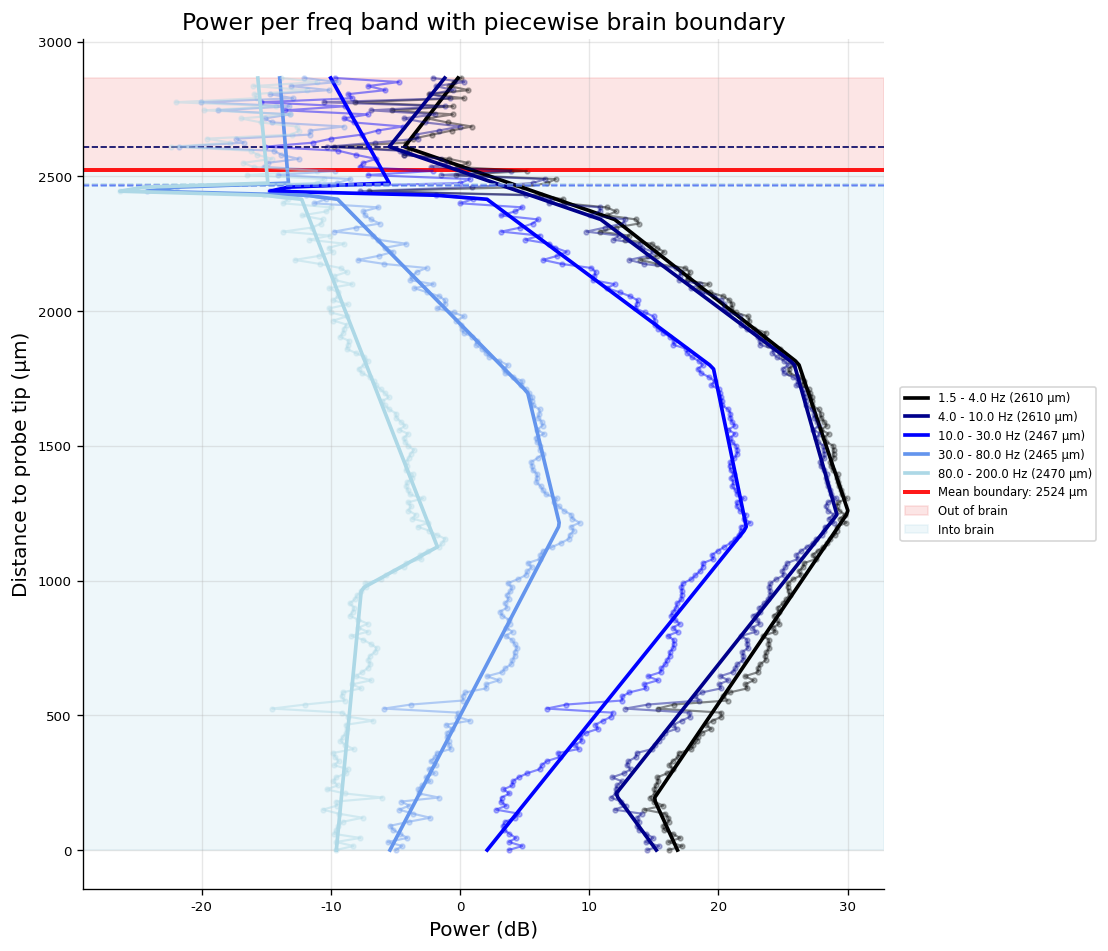

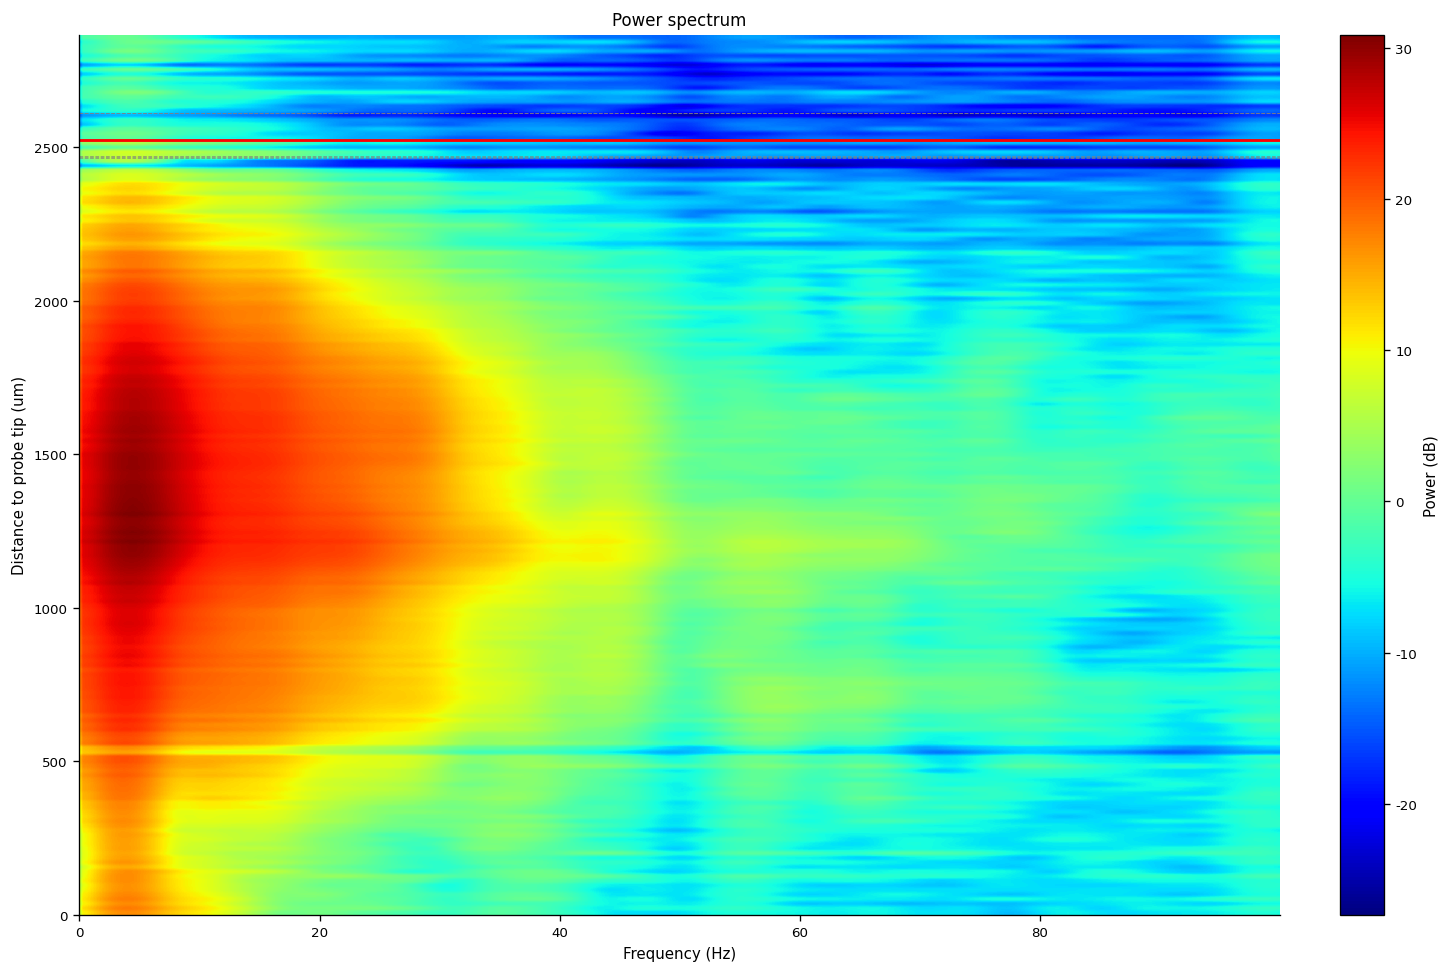

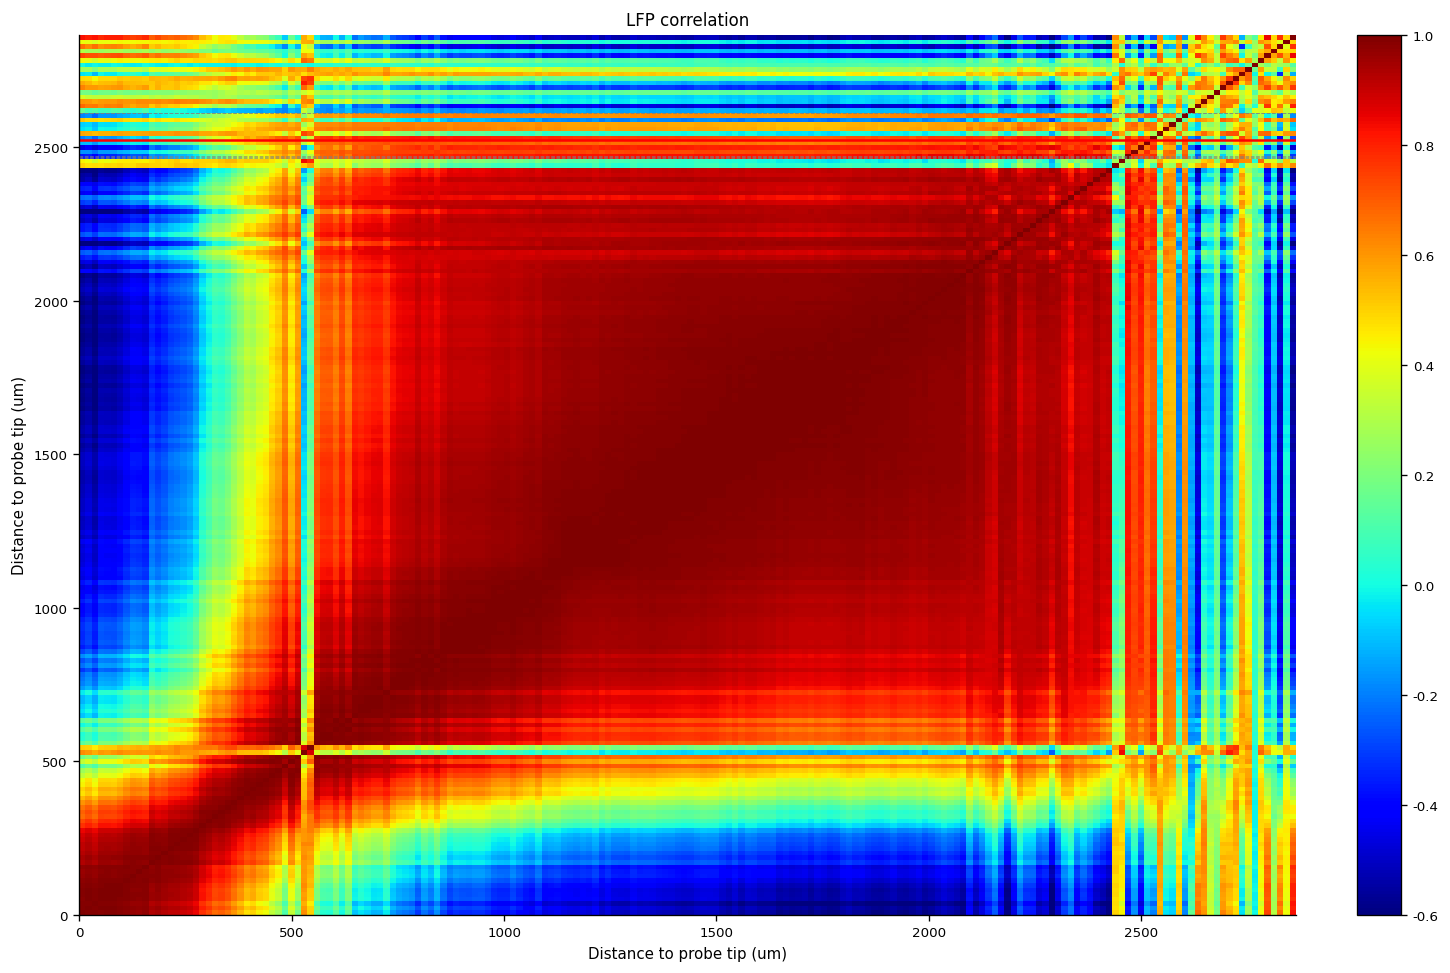

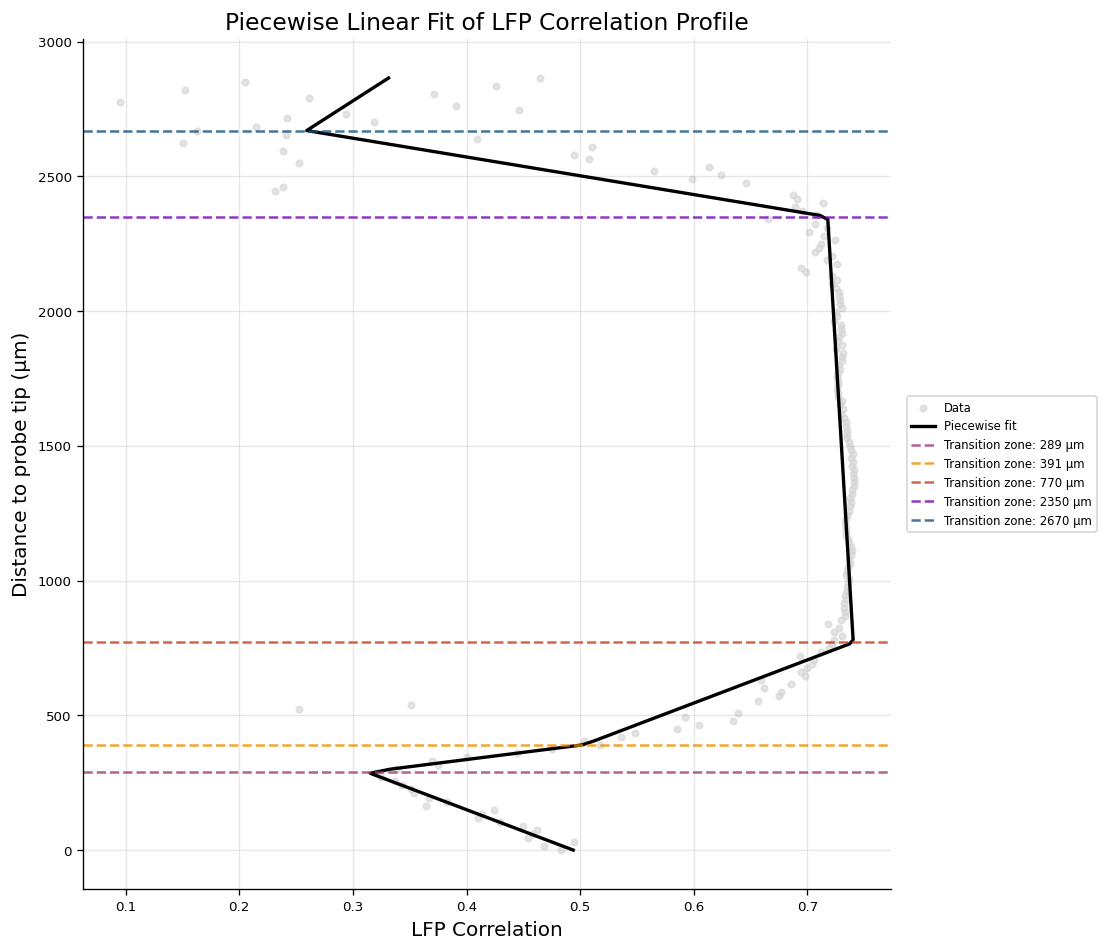

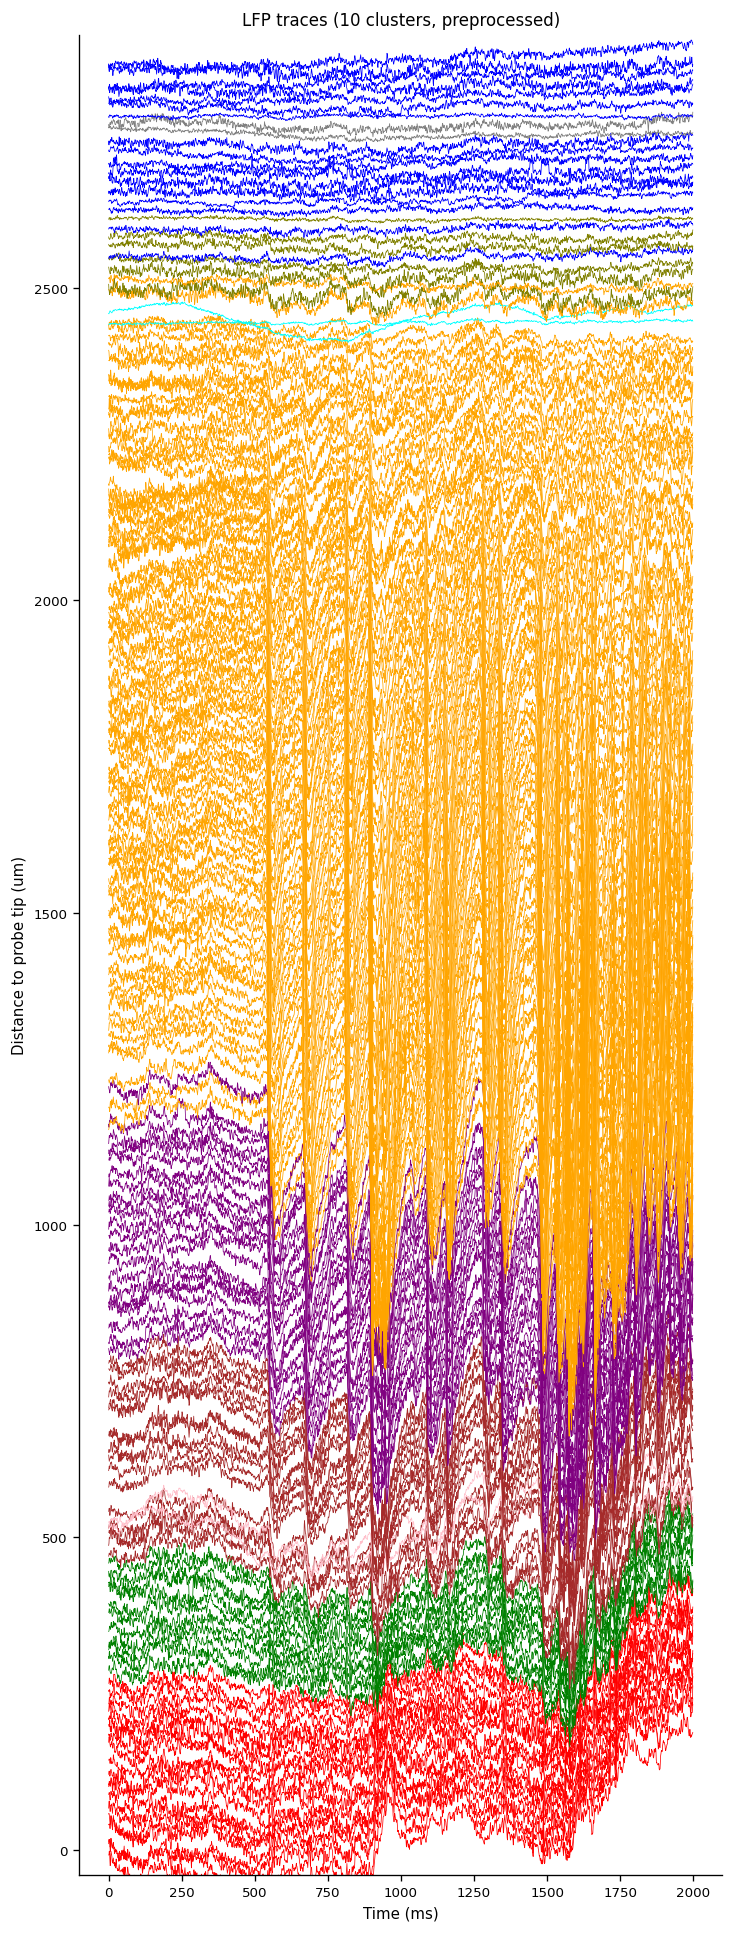

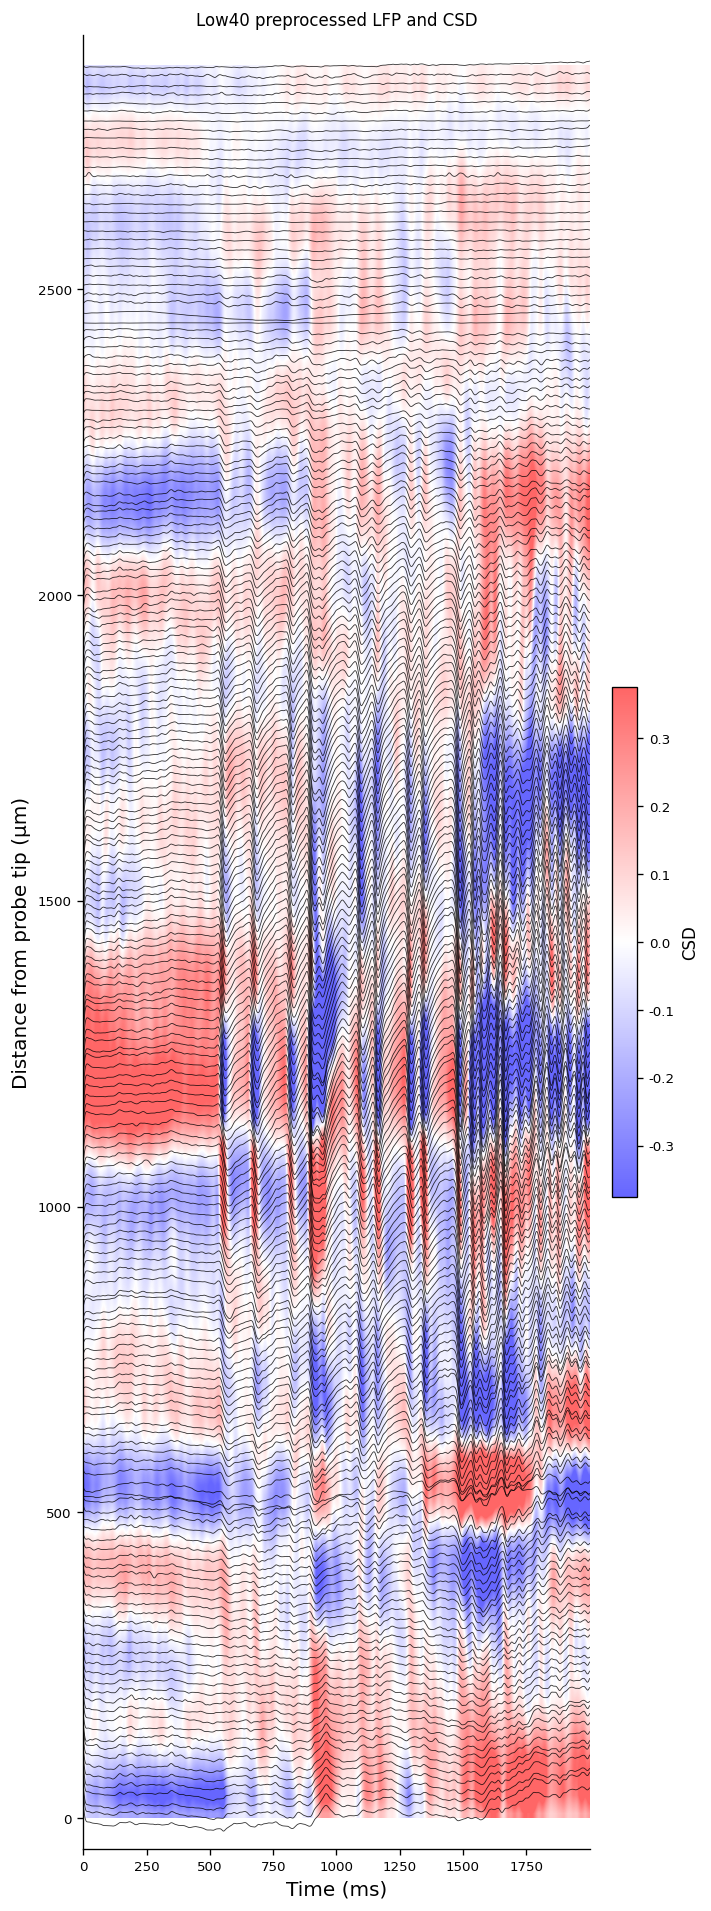

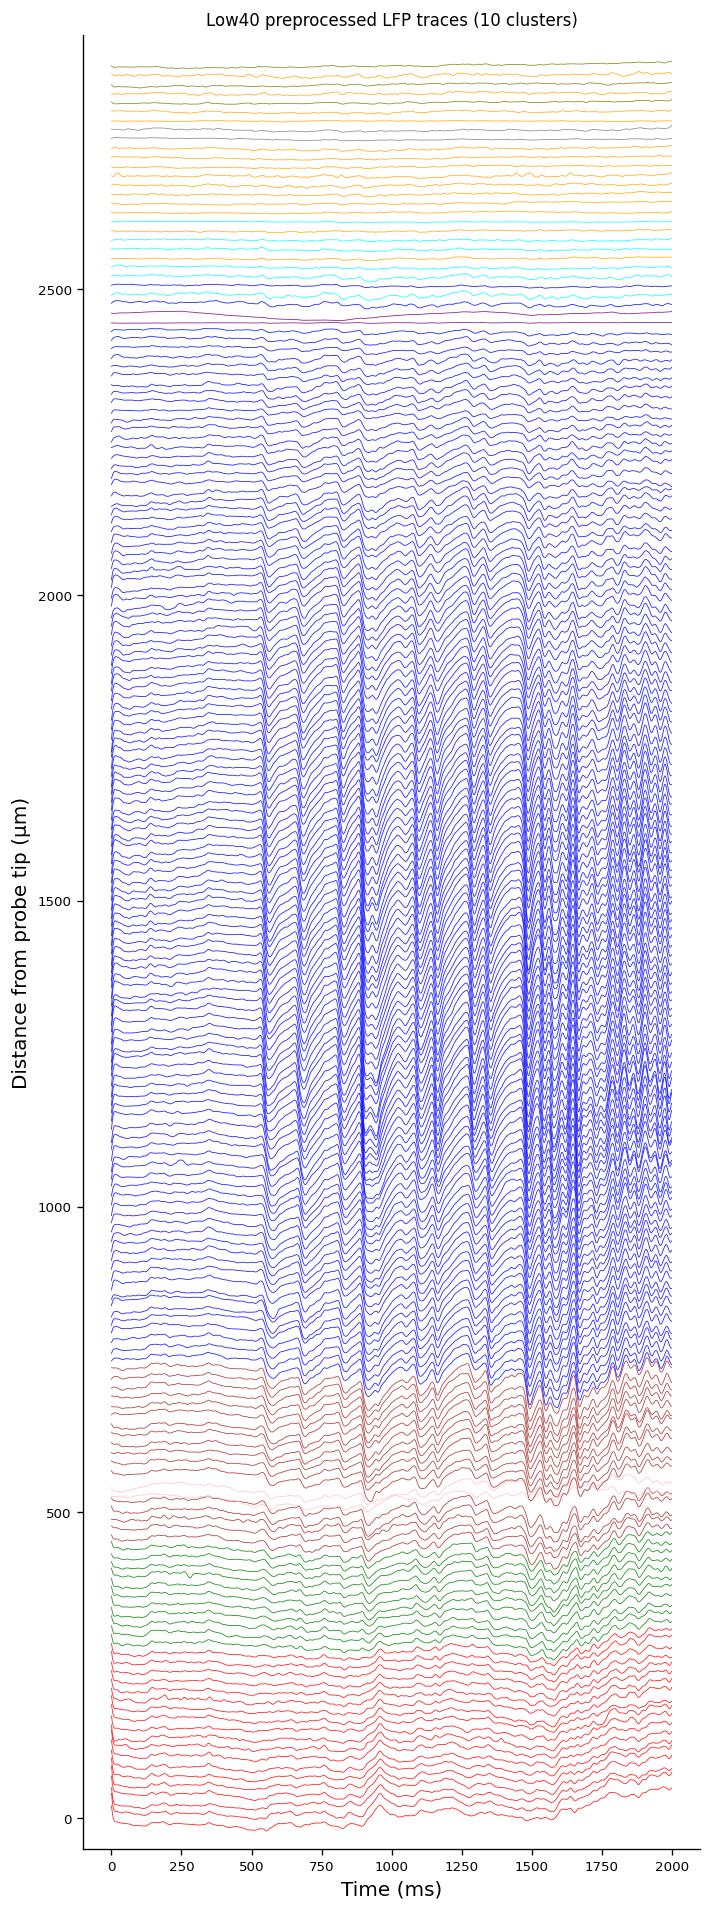

In [74]:
fig_a = plot_power_profiles_with_piecewise(depth_um, band_power, fits, boundaries, BRAIN_BOUNDARY_UM)
fig_b = plot_power_spectrum(depth_um, freqs, power_db, boundaries, BRAIN_BOUNDARY_UM)
fig_c = plot_lfp_correlation(depth_um, corr, boundaries, BRAIN_BOUNDARY_UM)
fig_d, lfp_corr_breaks = plot_lfp_correlation_piecewise(depth_um, corr)
fig_e = plot_lfp_traces(
    profile_data,
    profile_time,
    depth_um,
    cluster_labels=lfp_trace_cluster_labels,
    title=f"LFP traces ({N_LFP_TRACE_CLUSTERS} clusters, preprocessed)",
)

print("LFP correlation piecewise breakpoints:")
for i, bp in enumerate(lfp_corr_breaks[1:-1], 1):
    print(f"  Breakpoint {i}: {bp:.1f} μm")

figures = [("A", fig_a), ("B", fig_b), ("C", fig_c), ("D", fig_d), ("E", fig_e)]
PDF_PATH = save_figures_pdf(figures, PDF_PATH)
print(f"Saved PDF: {PDF_PATH}")

if MAKE_LOW40_PREPROCESSED_TRACE_PDF:
    low40_lfp_data, low40_lfp_time_ms, low40_lfp_c_factor, low40_csd, low40_new_fs = preprocess_low40_lfp_window(
        raw_data,
        raw_time,
        fs=metadata["sampling_rate"],
        start_s=float(profile_time[0]),
        duration_s=PROFILE_DURATION_S,
    )
    low40_lfp_corr = compute_correlation(low40_lfp_data)
    low40_lfp_cluster_labels = cluster_lfp_by_correlation(low40_lfp_corr, n_clusters=N_LFP_TRACE_CLUSTERS)
    fig_low40_csd = plot_low40_lfp_with_csd(
        low40_lfp_data,
        low40_lfp_time_ms,
        depth_um,
        low40_csd,
        title="Low40 preprocessed LFP and CSD",
    )
    fig_low40_no_csd = plot_low40_lfp_traces_no_csd(
        low40_lfp_data,
        low40_lfp_time_ms,
        depth_um,
        cluster_labels=low40_lfp_cluster_labels,
        title=f"Low40 preprocessed LFP traces ({N_LFP_TRACE_CLUSTERS} clusters)",
    )
    LOW40_PREPROCESSED_PDF_PATH = OUTPUT_DIR / f"{RECORDING_ID}_low40_preprocessed_lfp_traces.pdf"
    save_figures_pdf(
        [("low40_lfp_csd", fig_low40_csd), ("low40_lfp_no_csd", fig_low40_no_csd)],
        LOW40_PREPROCESSED_PDF_PATH,
    )
    print(f"Saved low40 preprocessed LFP PDF: {LOW40_PREPROCESSED_PDF_PATH}")
    print(f"Low40 preprocessed sampling rate: {low40_new_fs:.1f} Hz")
    print(f"Low40 preprocessed C-factor median range: {np.nanmin(low40_lfp_c_factor):.3f}-{np.nanmax(low40_lfp_c_factor):.3f}")

In [69]:
# Optional: save a compact table with the estimated boundary values next to the PDF.
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
summary_path = OUTPUT_DIR / f"{RECORDING_ID}_brain_boundary_summary.csv"
summary = pd.DataFrame({
    "frequency_band": list(boundary["per_band_um"].keys()) + ["mean", "median", "std"],
    "boundary_um": list(boundary["per_band_um"].values()) + [boundary["mean_um"], boundary["median_um"], boundary["std_um"]],
})
summary.to_csv(summary_path, index=False)
summary

,frequency_band,boundary_um
0,1.5-4 Hz,2610.000000
1,4-10 Hz,2610.000000
2,10-30 Hz,2467.381362
3,30-80 Hz,2465.006801
4,80-200 Hz,2469.947436
5,mean,2524.467120
6,median,2469.947436
7,std,69.854787
